# 09 · Interpretación del modelo final
**Proyecto Integrador ML2 — Entrega final · Predicción de la TRM**

**Objetivo (rúbrica 8.2).** Interpretar el modelo final (**CatBoost con solo la TRM**) en términos del problema: qué variables mueven su predicción y cómo, días concretos explicados, tipos de error y sus implicaciones, y alcance de las conclusiones, todo traducido al lenguaje de quien usa la TRM (un importador o una empresa con pagos en dólares).

**Técnicas.** SHAP (TreeExplainer, exacto para árboles) y dependencia parcial con curvas ICE. No se usa LIME: aproxima el modelo con otro modelo local y, para árboles, puede contradecir a SHAP, que aquí se calcula de forma exacta.

**Datos.** El modelo congelado de la Entrega 2 (entrenado con el desarrollo, 2003–2022) sobre el test (1.080 días, 2022–2026). El test ya se abrió en la Entrega 2: aquí solo se describe, no se elige nada.

**Partes.** 1) Qué mira el modelo (global). 2) Cuatro días explicados, elegidos con una regla fija. 3) Tipos de error y sus implicaciones prácticas. 4) Alcance de las conclusiones. 5) Traducción al contexto: qué significa para un importador y para el Banco de la República.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap
from scipy import stats
from IPython.display import display
from sklearn.inspection import partial_dependence

from src import config as cfg
from src.validacion import errores_en_pesos
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
FINAL, BASE = "CatBoost · solo_trm", "Línea base (lineal)"
VARS = cfg.VARS_TRM
NOMBRE = {"r_trm_l1": "Movimiento de hoy", "r_trm_l5": "Hace 5 TRM", "r_trm_l10": "Hace 10 TRM"}

modelos = joblib.load(cfg.MODELOS / "modelos_finales.joblib")
final, lineal = modelos[FINAL], modelos[BASE]
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
datos["vol20"] = datos["r_trm_l1"].rolling(20).std()                       # volatilidad de las últimas 20 TRM (solo pasado)
test = datos[datos["muestra"] == "test"].reset_index(drop=True)
X = test[VARS]
pt = pd.read_csv(cfg.DATA_PROC / "predicciones_test.csv", parse_dates=["fecha"])
assert np.allclose(final.predict(X), pt[FINAL]) and np.allclose(lineal.predict(X), pt[BASE])   # es el modelo evaluado
exp = shap.TreeExplainer(final.named_steps["modelo"])
sv = exp.shap_values(X)
BASE_SHAP = float(np.ravel(exp.expected_value)[0])
assert np.allclose(sv.sum(axis=1) + BASE_SHAP, pt[FINAL])                    # SHAP suma la predicción
pendiente_lineal = lineal.named_steps["modelo"].coef_ / lineal.named_steps["escala"].scale_
print(f"Test: {len(test):,} días · valor base SHAP {1e4 * BASE_SHAP:+.2f} pb · pendientes de la lineal:",
      dict(zip(VARS, np.round(pendiente_lineal, 4))))

/Users/nicolas/dev/entornos/entornos/ml/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Test: 1,080 días · valor base SHAP +0.78 pb · pendientes de la lineal: {'r_trm_l1': np.float64(0.1652), 'r_trm_l5': np.float64(-0.0076), 'r_trm_l10': np.float64(0.0286)}


## 1. Qué mira el modelo final (interpretación global)
**Dependencia parcial:** cómo cambia la predicción cuando cambia una variable y las demás se dejan como están (promedio sobre los días del test); cada curva ICE es un día. Se compara con la recta de la regresión lineal. De la curva del movimiento de hoy se miden tres cosas: la **pendiente en el centro** (qué fracción de un movimiento pequeño se repite mañana), el **techo** (la predicción máxima que alcanza) y el **punto de quiebre** (desde qué tamaño de movimiento ya no sube).

In [2]:
def curva(var, n=80):
    '''Dependencia parcial e ICE de una variable del modelo final sobre el test.

    Parámetros
    ----------
    var : str
        Variable del modelo.
    n : int, por defecto 80
        Puntos de la grilla, entre los percentiles 0,5 y 99,5 del test.

    Devuelve
    --------
    tuple[np.ndarray, np.ndarray, np.ndarray]
        Grilla (retorno), promedio (dependencia parcial) e ICE (una fila por día), en retorno.
    '''
    r = partial_dependence(final, X, [var], kind="both", grid_resolution=n, percentiles=(0.005, 0.995))
    return r["grid_values"][0], r["average"][0], r["individual"][0]

curvas = {v: curva(v) for v in VARS}
g, pdp, _ = curvas["r_trm_l1"]
pdp0 = np.interp(0.0, g, pdp)                                    # predicción con movimiento de hoy = 0
centro = np.abs(g) <= 0.004                                       # movimientos de hasta ±0,4 %
pendiente_central = np.polyfit(g[centro], pdp[centro], 1)[0]
techo_sube, techo_baja = pdp.max() - pdp0, pdp.min() - pdp0
quiebre_sube = g[np.argmax(pdp - pdp0 >= 0.9 * techo_sube)]       # primer punto que alcanza el 90 % del techo
quiebre_baja = g[::-1][np.argmax((pdp - pdp0)[::-1] <= 0.9 * techo_baja)]
ejemplo = {f"{p:+.1f} %": {"lineal_pb": 1e4 * pendiente_lineal[0] * p / 100,
                           "modelo_final_pb": 1e4 * (np.interp(p / 100, g, pdp) - pdp0)} for p in (0.5, 1, 2, 3, -1, -2)}

importancia = pd.DataFrame({
    "importancia_pct": 100 * np.abs(sv).mean(axis=0) / np.abs(sv).mean(axis=0).sum(),
    "direccion_spearman": [stats.spearmanr(X[v], sv[:, i]).statistic for i, v in enumerate(VARS)],
    "pendiente_lineal": pendiente_lineal,
    "rango_efecto_pb": [1e4 * (curvas[v][1].max() - curvas[v][1].min()) for v in VARS],
}, index=pd.Index(VARS, name="variable"))
forma = pd.Series({"pendiente_central_modelo_final": pendiente_central, "pendiente_lineal": pendiente_lineal[0],
                   "techo_sube_pb": 1e4 * techo_sube, "techo_baja_pb": 1e4 * techo_baja,
                   "quiebre_sube_pct": 100 * quiebre_sube, "quiebre_baja_pct": 100 * quiebre_baja}, name="movimiento_de_hoy")
guardar_tabla(importancia, "tab15_importancia_modelo_final")
display(importancia); display(forma.to_frame())
display(pd.DataFrame(ejemplo).T.rename_axis("movimiento de hoy"))

,importancia_pct,direccion_spearman,pendiente_lineal,rango_efecto_pb
variable,,,,
r_trm_l1,81.9541,0.9827,0.1652,59.4739
r_trm_l5,5.2192,-0.4676,-0.0076,17.3182
r_trm_l10,12.8268,0.8016,0.0286,15.0693


,movimiento_de_hoy
pendiente_central_modelo_final,0.2015
pendiente_lineal,0.1652
techo_sube_pb,35.2639
techo_baja_pb,-24.2100
quiebre_sube_pct,1.7573
quiebre_baja_pct,-1.5074


,lineal_pb,modelo_final_pb
movimiento de hoy,,
+0.5 %,8.2590,13.6595
+1.0 %,16.5179,21.8620
+2.0 %,33.0358,35.1741
+3.0 %,49.5537,35.2639
-1.0 %,-16.5179,-18.3740
-2.0 %,-33.0358,-24.2100


**Interacciones.** ¿El efecto del movimiento de hoy depende de los de hace 5 o 10 días? Se mide con los valores de interacción SHAP: qué parte del aporte total viene de combinaciones de variables y no de cada una por separado.

In [3]:
from catboost import Pool
cat = final.named_steps["modelo"]
inter = cat.get_feature_importance(Pool(X), type="ShapInteractionValues")[:, :-1, :-1]   # días × var × var (sin la columna del sesgo)
total = np.abs(inter).sum(axis=(1, 2)).mean()
cruzado = (np.abs(inter).sum(axis=(1, 2)) - np.abs(np.diagonal(inter, axis1=1, axis2=2)).sum(axis=1)).mean()
pares = pd.Series({f"{NOMBRE[VARS[i]]} × {NOMBRE[VARS[j]]}": 2 * np.abs(inter[:, i, j]).mean() / total * 100
                   for i in range(3) for j in range(i + 1, 3)}, name="pct_del_aporte_total")
assert np.allclose(inter.sum(axis=2), sv, atol=1e-10)              # las interacciones reconstruyen los SHAP
forma["interaccion_pct"] = 100 * cruzado / total
guardar_tabla(pd.concat([forma, pares]).to_frame("valor"), "tab15a_forma_e_interacciones")
print(f"Parte del aporte que viene de interacciones: {100 * cruzado / total:.1f} %")
display(pares.to_frame())

Parte del aporte que viene de interacciones: 8.3 %


,pct_del_aporte_total
Movimiento de hoy × Hace 5 TRM,4.1044
Movimiento de hoy × Hace 10 TRM,2.2928
Hace 5 TRM × Hace 10 TRM,1.8987


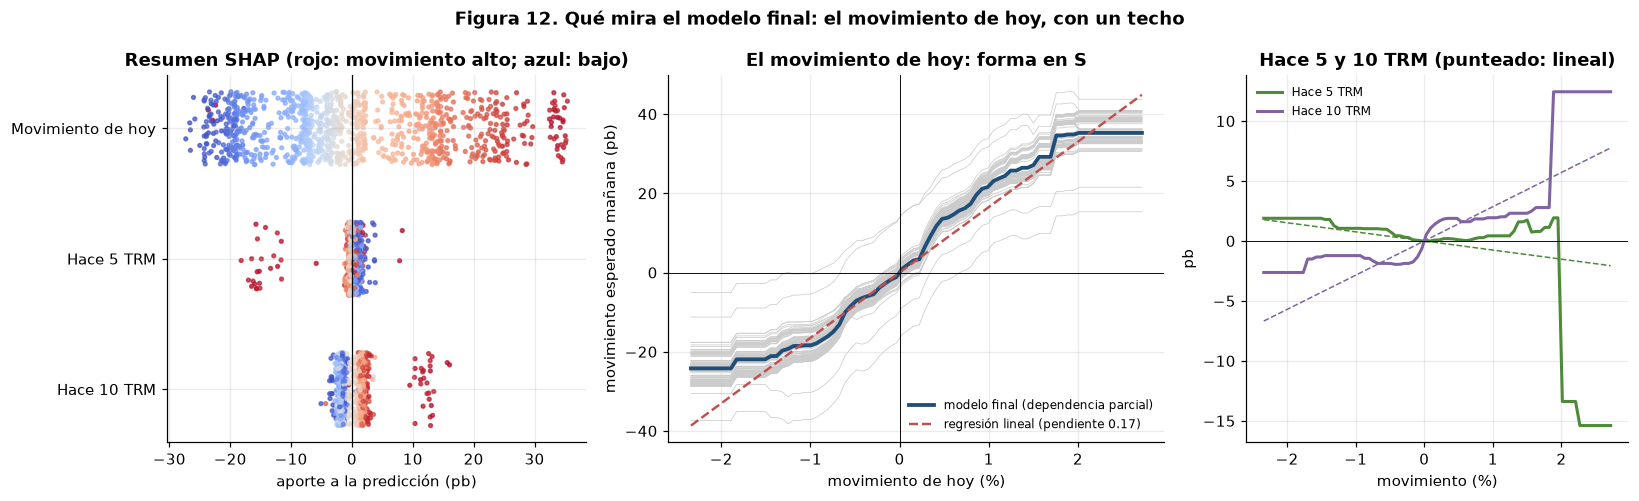

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1.3, 1]})
eje = ejes[0]
rng = np.random.default_rng(cfg.SEMILLA)
for i, v in enumerate(VARS[::-1]):
    k = VARS.index(v)
    rango = X[v].rank(pct=True)
    eje.scatter(1e4 * sv[:, k], np.full(len(X), i) + rng.uniform(-0.28, 0.28, len(X)), c=rango, cmap="coolwarm", s=6, alpha=0.7)
eje.axvline(0, color="k", lw=0.8)
eje.set(yticks=range(3), yticklabels=[NOMBRE[v] for v in VARS[::-1]], xlabel="aporte a la predicción (pb)",
        title="Resumen SHAP (rojo: movimiento alto; azul: bajo)")
eje = ejes[1]
g, pdp, ice = curvas["r_trm_l1"]
for fila in ice[rng.choice(len(ice), 120, replace=False)]:
    eje.plot(100 * g, 1e4 * (fila - pdp0), color="0.8", lw=0.5)
eje.plot(100 * g, 1e4 * (pdp - pdp0), color=COLORES[0], lw=2.5, label="modelo final (dependencia parcial)")
eje.plot(100 * g, 1e4 * pendiente_lineal[0] * g, color=COLORES[1], lw=1.6, ls="--", label=f"regresión lineal (pendiente {pendiente_lineal[0]:.2f})")
eje.axhline(0, color="k", lw=0.6); eje.axvline(0, color="k", lw=0.6)
eje.set(xlabel="movimiento de hoy (%)", ylabel="movimiento esperado mañana (pb)", title="El movimiento de hoy: forma en S")
eje.legend(frameon=False, fontsize=8)
eje = ejes[2]
for v, c in [("r_trm_l5", COLORES[2]), ("r_trm_l10", COLORES[3])]:
    gv, pv, _ = curvas[v]
    eje.plot(100 * gv, 1e4 * (pv - np.interp(0, gv, pv)), color=c, lw=2, label=NOMBRE[v])
    eje.plot(100 * gv, 1e4 * pendiente_lineal[VARS.index(v)] * gv, color=c, lw=1, ls="--")
eje.axhline(0, color="k", lw=0.6)
eje.set(xlabel="movimiento (%)", ylabel="pb", title="Hace 5 y 10 TRM (punteado: lineal)")
eje.legend(frameon=False, fontsize=8)
fig.suptitle("Figura 12. Qué mira el modelo final: el movimiento de hoy, con un techo", fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig12_interpretacion_global"); plt.show()

### Lectura de la parte 1: qué mira el modelo final
**1. Casi todo depende del movimiento de hoy (Tabla 15, Figura 12 izquierda).** El movimiento de la TRM de ese día concentra el **82 %** de la importancia SHAP y empuja la predicción en su misma dirección (Spearman +0,98): si hoy subió, el modelo espera que mañana suba un poco; si bajó, que baje. Los movimientos de hace 10 y 5 TRM pesan 13 % y 5 %.

**2. La forma en S se confirma en el modelo final (Figura 12 centro).**
- **En el centro se parece a la regresión lineal:** para movimientos de hasta ±0,4 %, el modelo repite el **20 %** del movimiento de hoy (la lineal, el 17 %).
- **Pero tiene techo:** al subir, el efecto deja de crecer desde **+1,8 %** y se queda en **+35 pb**; al bajar, desde **−1,5 %** y se queda en **−24 pb**. La regresión lineal sigue creciendo sin límite.
- **En cifras:** si hoy la TRM sube 1 %, la lineal espera +17 pb y el modelo +22 pb; si sube 3 %, la lineal espera +50 pb y el modelo se queda en +35 pb; si baja 2 %, la lineal espera −33 pb y el modelo −24 pb.
- **Asimetría:** el techo de subida (+35 pb) es mayor que el de bajada (−24 pb). El modelo aprendió que, en 2003–2022, las devaluaciones tendieron a continuar más que las revaluaciones.

**3. El pasado más lejano casi no cuenta (Figura 12 derecha).** Los movimientos de hace 5 y 10 TRM mueven la predicción ±2 pb, salvo después de saltos de más de ~2 %: ahí el modelo aplica reglas fuertes (−15 pb tras un salto grande hace 5 TRM; +12 pb tras uno hace 10). Esas reglas salen de **63 días** del desarrollo (1,5 %) y la regresión lineal casi no les da peso: son patrones de pocos casos y se leen con cautela.

**4. Los efectos casi no se combinan.** Solo el **8 %** del aporte total viene de interacciones entre variables (la mayor, hoy × hace 5 TRM, 4 %): el modelo suma efectos casi independientes, lo esperable con árboles de profundidad 2.

**En palabras de un importador:** *mañana la TRM suele repetir cerca de una quinta parte del movimiento de hoy, pero con un tope: si hoy subió o bajó mucho, el modelo no espera que mañana siga en la misma proporción. Con la TRM en 4.000 pesos, el máximo que espera es unos 14 pesos al alza o 10 a la baja. Lo que pasó hace una o dos semanas casi no importa.*

## 2. Cuatro días explicados
Los días se eligen con una **regla fija**, para no escoger los que "salen bien": (a) un **día típico**, cuyo error absoluto es el más cercano a la mediana; (b) el día con el **mayor movimiento predicho**; (c) el día con el **mayor error**; (d) el día de **mayor volatilidad** de las 20 TRM anteriores. Si dos reglas eligen el mismo día, se toma el siguiente de la segunda.

In [5]:
d = test.assign(pred=pt[FINAL].to_numpy(), pred_lineal=pt[BASE].to_numpy())
d["trm_pred"] = d["trm"] * np.exp(d["pred"])
d["trm_pred_lineal"] = d["trm"] * np.exp(d["pred_lineal"])
d["error"] = errores_en_pesos(d["y"], d["pred"], d["trm"])                # real − predicho, en pesos
d["error_lineal"] = errores_en_pesos(d["y"], d["pred_lineal"], d["trm"])
reglas = {
    "Día típico": (d["error"].abs() - d["error"].abs().median()).abs().sort_values().index,
    "Mayor movimiento predicho": d["pred"].abs().sort_values(ascending=False).index,
    "Mayor error": d["error"].abs().sort_values(ascending=False).index,
    "Mayor volatilidad": d["vol20"].sort_values(ascending=False).index,
}
elegidos = {}
for nombre, orden in reglas.items():
    elegidos[nombre] = next(i for i in orden if i not in elegidos.values())

filas = []
for nombre, i in elegidos.items():
    f = d.loc[i]
    filas.append({"regla": nombre, "fecha": f["fecha"].date(), "trm_hoy": f["trm"],
                  "mov_hoy_pct": 100 * f["r_trm_l1"], "mov_5_pct": 100 * f["r_trm_l5"], "mov_10_pct": 100 * f["r_trm_l10"],
                  "vol_anual_pct": 100 * np.sqrt(252) * f["vol20"],
                  "aporte_base_pb": 1e4 * BASE_SHAP, **{f"aporte_{v}_pb": 1e4 * sv[i, k] for k, v in enumerate(VARS)},
                  "pred_pb": 1e4 * f["pred"], "trm_predicha": f["trm_pred"], "trm_predicha_lineal": f["trm_pred_lineal"],
                  "trm_real_siguiente": f["trm_sig"], "mov_real_pb": 1e4 * f["y"],
                  "error_pesos": f["error"], "error_lineal_pesos": f["error_lineal"]})
dias = pd.DataFrame(filas).set_index("regla")
guardar_tabla(dias, "tab15b_dias_explicados")
display(dias.T)

regla,Día típico,Mayor movimiento predicho,Mayor error,Mayor volatilidad
fecha,2026-01-17,2023-02-17,2023-10-07,2022-08-03
trm_hoy,"3,700.0500","4,966.3300","4,386.6600","4,313.3000"
mov_hoy_pct,0.3446,1.7897,0.6234,1.5728
mov_5_pct,-0.4718,0.7496,2.1396,-0.5473
mov_10_pct,0.8927,1.8435,2.5957,-0.2801
vol_anual_pct,13.4310,18.3775,17.0076,25.7932
aporte_base_pb,0.7783,0.7783,0.7783,0.7783
aporte_r_trm_l1_pb,7.4822,34.6505,13.6543,27.0455
aporte_r_trm_l5_pb,-0.0895,1.0076,-15.5277,0.2532
aporte_r_trm_l10_pb,1.6567,3.0571,9.5015,-2.4155


In [6]:
def es(x, decimales=2, signo=False):
    '''Escribe un número con punto de miles y coma decimal (formato colombiano).

    Parámetros
    ----------
    x : float
        Número.
    decimales : int, por defecto 2
        Decimales.
    signo : bool, por defecto False
        Antepone "+" a los positivos.

    Devuelve
    --------
    str
        El número formateado.
    '''
    t = f"{x:{'+' if signo else ''},.{decimales}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")


def frase(nombre, f):
    '''Explica en lenguaje sencillo la predicción de un día.

    Parámetros
    ----------
    nombre : str
        Regla con que se eligió el día.
    f : pd.Series
        Fila de la tabla `dias`.

    Devuelve
    --------
    str
        Explicación de dos o tres frases.
    '''
    verbo = "subió" if f["mov_hoy_pct"] > 0 else "bajó"
    resto = f["aporte_r_trm_l5_pb"] + f["aporte_r_trm_l10_pb"]
    return (f"{nombre} ({f['fecha']:%d/%m/%Y}). La TRM estaba en $ {es(f['trm_hoy'])} y ese día {verbo} {es(abs(f['mov_hoy_pct']))} %. "
            f"El modelo esperaba {es(f['pred_pb'], 1, True)} pb para la siguiente: {es(f['aporte_r_trm_l1_pb'], 1, True)} pb por el movimiento "
            f"de ese día y {es(resto, 1, True)} pb por los de hace 5 y 10 TRM. Es decir, $ {es(f['trm_predicha'])} "
            f"(la lineal, $ {es(f['trm_predicha_lineal'])}). La TRM siguiente fue $ {es(f['trm_real_siguiente'])} "
            f"({es(f['mov_real_pb'], 0, True)} pb): error de {es(f['error_pesos'], 2, True)} pesos (lineal: {es(f['error_lineal_pesos'], 2, True)}).")

for nombre, f in dias.iterrows():
    print(frase(nombre, f), "\n")

Día típico (17/01/2026). La TRM estaba en $ 3.700,05 y ese día subió 0,34 %. El modelo esperaba +9,8 pb para la siguiente: +7,5 pb por el movimiento de ese día y +1,6 pb por los de hace 5 y 10 TRM. Es decir, $ 3.703,69 (la lineal, $ 3.703,47). La TRM siguiente fue $ 3.682,97 (-46 pb): error de -20,72 pesos (lineal: -20,50). 

Mayor movimiento predicho (17/02/2023). La TRM estaba en $ 4.966,33 y ese día subió 1,79 %. El modelo esperaba +39,5 pb para la siguiente: +34,7 pb por el movimiento de ese día y +4,1 pb por los de hace 5 y 10 TRM. Es decir, $ 4.985,98 (la lineal, $ 4.983,69). La TRM siguiente fue $ 4.918,94 (-96 pb): error de -67,04 pesos (lineal: -64,75). 

Mayor error (07/10/2023). La TRM estaba en $ 4.386,66 y ese día subió 0,62 %. El modelo esperaba +8,4 pb para la siguiente: +13,7 pb por el movimiento de ese día y -6,0 pb por los de hace 5 y 10 TRM. Es decir, $ 4.390,35 (la lineal, $ 4.394,00). La TRM siguiente fue $ 4.231,97 (-359 pb): error de -158,38 pesos (lineal: -162,0

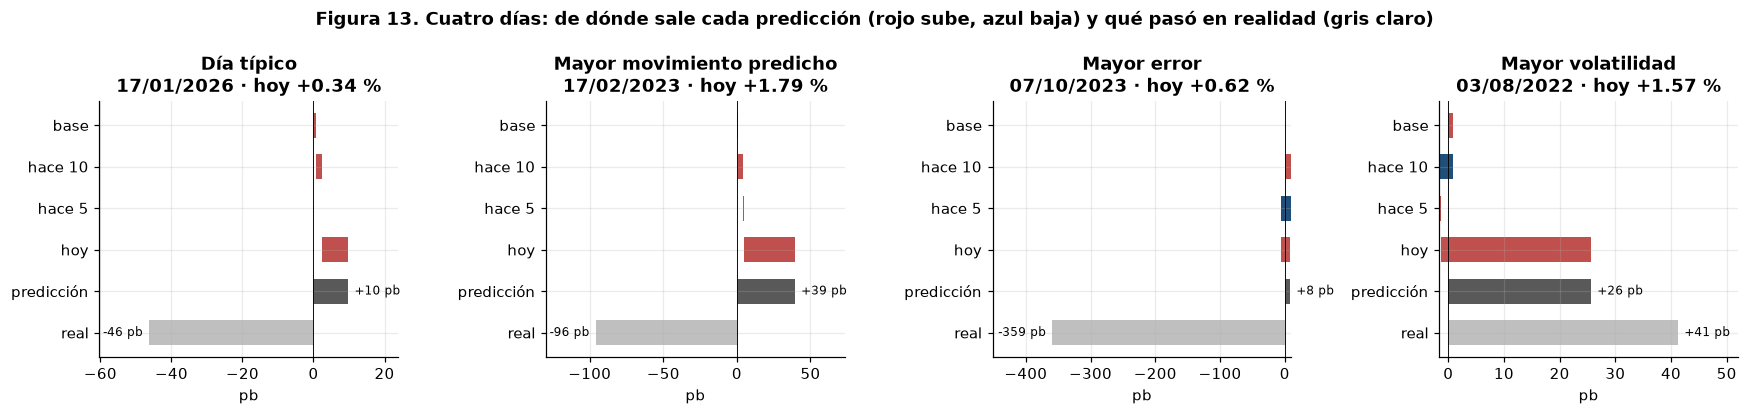

In [7]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=False)
etiquetas = ["base", "hace 10", "hace 5", "hoy", "predicción", "real"]
for eje, (nombre, f) in zip(ejes, dias.iterrows()):
    pasos = [f["aporte_base_pb"], f["aporte_r_trm_l10_pb"], f["aporte_r_trm_l5_pb"], f["aporte_r_trm_l1_pb"]]
    acumulado = np.concatenate([[0], np.cumsum(pasos)])
    for k, p in enumerate(pasos):
        eje.barh(len(etiquetas) - 1 - k, p, left=acumulado[k], color=COLORES[1] if p > 0 else COLORES[0], height=0.6)
    eje.barh(1, f["pred_pb"], color="0.35", height=0.6)
    eje.barh(0, f["mov_real_pb"], color="0.75", height=0.6)
    for y, v in [(1, f["pred_pb"]), (0, f["mov_real_pb"])]:
        eje.annotate(f"{v:+.0f} pb", (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                     ha="left" if v >= 0 else "right", va="center", fontsize=8)
    eje.margins(x=0.25)
    eje.axvline(0, color="k", lw=0.6)
    eje.set(yticks=range(len(etiquetas))[::-1], yticklabels=etiquetas, xlabel="pb",
            title=f"{nombre}\n{f['fecha']:%d/%m/%Y} · hoy {f['mov_hoy_pct']:+.2f} %")
fig.suptitle("Figura 13. Cuatro días: de dónde sale cada predicción (rojo sube, azul baja) y qué pasó en realidad (gris claro)",
             fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig13_dias_explicados"); plt.show()

### Lectura de la parte 2: cuatro días
- **Día típico (17/01/2026).** La TRM subió 0,34 % y el modelo esperaba +10 pb (casi todo por ese movimiento). La siguiente bajó 46 pb: error de −20,7 pesos, cercano al error típico del test (27). **Así es un día normal:** la predicción es pequeña y lo que realmente pasa lo decide información nueva del día siguiente.
- **Mayor movimiento predicho (17/02/2023).** Tras una subida de 1,79 %, el modelo llegó casi a su techo (+39 pb). La TRM siguiente cayó 96 pb: error de −67 pesos. **Ni la mayor continuación que espera el modelo es segura:** un salto grande también puede devolverse.
- **Mayor error (07/10/2023).** Un movimiento moderado (+0,62 %) llevó a esperar +8 pb, pero la TRM siguiente cayó **3,6 %** (−158 pesos), en plena revaluación de octubre de 2023. **Los grandes saltos no se anticipan** con el movimiento de los días anteriores: ninguna variable del modelo contenía esa información.
- **Mayor volatilidad (03/08/2022, 25,8 % anual).** Tras una subida de 1,57 %, el modelo esperó +26 pb y la TRM subió 41 pb: error de +6,8 pesos. Aquí la continuación sí ocurrió.
- **En los cuatro días la regresión lineal se equivoca casi igual** (diferencias de menos de 4 pesos), como era de esperarse por el empate estadístico.

**Lo que muestran juntos:** la explicación es siempre la misma (cuánto se movió la TRM ese día), y el error viene de lo que pasa después. El modelo da un **punto de referencia razonable**, pero no anticipa los movimientos grandes; eso se mide de forma sistemática en la parte 3.

## 3. Tipos de error y sus implicaciones prácticas
Sobre los 1.080 días del test, para el modelo final, la regresión lineal y una tercera referencia que usa cualquier importador sin modelo: **"mañana igual que hoy"** (predecir cero movimiento). Se mide: (1) si el modelo acierta la **dirección**; (2) cuánto se equivoca según el **tamaño del movimiento real**, la **volatilidad** y la **dirección**; (3) si el **rango del 80 %** que muestra la aplicación contiene de verdad la TRM el 80 % de las veces; y (4) cuánto es el error **en pesos** para una compra de USD 100.000.

In [8]:
d["error_ingenuo"] = errores_en_pesos(d["y"], 0.0, d["trm"])            # "mañana igual que hoy"
MODELOS_ERR = {"Modelo final": "error", "Regresión lineal": "error_lineal", "Mañana igual que hoy": "error_ingenuo"}
mov = d[d["y"] != 0]                                                     # días con movimiento (para la dirección)
acierto = (np.sign(mov["pred"]) == np.sign(mov["y"]))
fuerza = pd.qcut(mov["pred"].abs(), 3, labels=["predicción débil", "predicción media", "predicción fuerte"])
direccion = pd.DataFrame({
    "dias": mov.groupby(fuerza, observed=True).size(),
    "acierto_direccion_pct": 100 * acierto.groupby(fuerza, observed=True).mean(),
    "acierto_direccion_lineal_pct": 100 * (np.sign(mov["pred_lineal"]) == np.sign(mov["y"])).groupby(fuerza, observed=True).mean(),
})
direccion.loc["todos"] = [len(mov), 100 * acierto.mean(), 100 * (np.sign(mov["pred_lineal"]) == np.sign(mov["y"])).mean()]
dias_sube = 100 * (mov["y"] > 0).mean()
binom = stats.binomtest(int(acierto.sum()), len(mov), p=max(dias_sube, 100 - dias_sube) / 100, alternative="greater")
guardar_tabla(direccion, "tab15c_acierto_direccion")
display(direccion)
print(f"Días en que la TRM subió: {dias_sube:.1f} %. ¿El modelo acierta la dirección más que "
      f"'decir siempre lo más frecuente' ({max(dias_sube, 100 - dias_sube):.1f} %)? p = {binom.pvalue:.4f}")

,dias,acierto_direccion_pct,acierto_direccion_lineal_pct
pred,,,
predicción débil,360,50.0000,46.1111
predicción media,360,56.6667,56.3889
predicción fuerte,360,58.8889,59.1667
todos,1080,55.1852,53.8889


Días en que la TRM subió: 46.4 %. ¿El modelo acierta la dirección más que 'decir siempre lo más frecuente' (53.6 %)? p = 0.1570


In [9]:
tamano = pd.cut(d["y"].abs(), [-1, d["y"].abs().quantile(0.5), d["y"].abs().quantile(0.9), 1],
                labels=["tranquilo (50 % más pequeño)", "normal (siguiente 40 %)", "grande (10 % más grande)"])
cortes_vol = datos.loc[datos["muestra"] == "desarrollo", "vol20"].quantile([1 / 3, 2 / 3]).to_numpy()   # terciles del desarrollo
volat = pd.cut(d["vol20"], [-1, *cortes_vol, 1], labels=["volatilidad baja", "volatilidad media", "volatilidad alta"])
sentido = np.where(d["y"] > 0, "la TRM subió", "la TRM bajó o no cambió")

def resumen(grupo):
    '''MAE en pesos de los tres pronósticos dentro de cada grupo de días.

    Parámetros
    ----------
    grupo : array-like
        Etiqueta de grupo de cada día del test.

    Devuelve
    --------
    pd.DataFrame
        Días y MAE de cada pronóstico por grupo.
    '''
    t = d.groupby(grupo, observed=True)
    return pd.DataFrame({"dias": t.size(), **{f"mae_{k}": t[c].apply(lambda e: e.abs().mean()) for k, c in MODELOS_ERR.items()}})

por_tamano, por_vol, por_sentido = resumen(tamano), resumen(volat), resumen(sentido)
e2 = np.sort(d["error"].to_numpy() ** 2)[::-1]
peso_extremos = {f"top_{p}pct_dias": 100 * e2[: int(len(e2) * p / 100)].sum() / e2.sum() for p in (1, 5, 10)}
sesgo = {k: d[c].mean() for k, c in MODELOS_ERR.items()}
errores = pd.concat({"tamaño del movimiento real": por_tamano, "volatilidad (20 TRM)": por_vol, "dirección real": por_sentido})
guardar_tabla(errores, "tab15d_error_por_tipo_de_dia")
display(errores)
print("Parte del error cuadrático del modelo final que viene de los días más extremos (%):",
      {k: round(v, 1) for k, v in peso_extremos.items()})
print("Error medio (real − predicho, pesos; > 0 = la TRM terminó más alta de lo predicho):", {k: round(v, 2) for k, v in sesgo.items()})

dias  \
tamaño del movimiento real tranquilo (50 % más pequeño)   540   
                           normal (siguiente 40 %)        432   
                           grande (10 % más grande)       108   
volatilidad (20 TRM)       volatilidad baja                51   
                           volatilidad media              362   
                           volatilidad alta               667   
dirección real             la TRM bajó o no cambió        579   
                           la TRM subió                   501   

                                                         mae_Modelo final  \
tamaño del movimiento real tranquilo (50 % más pequeño)           10.9692   
                           normal (siguiente 40 %)                34.5295   
                           grande (10 % más grande)               77.9516   
volatilidad (20 TRM)       volatilidad baja                       18.6400   
                           volatilidad media                      22.4313   
                           volatilidad alta                       30.2670   
dirección real             la TRM bajó o no cambió                25.9254   
                           la TRM subió                           28.4393   

                                                         mae_Regresión lineal  \
tamaño del movimiento real tranquilo (50 % más pequeño)               10.8091   
                           normal (siguiente 40 %)                    34.7875   
                           grande (10 % más grande)                   77.8063   
volatilidad (20 TRM)       volatilidad baja                           18.6744   
                           volatilidad media                          22.4526   
                           volatilidad alta                           30.2668   
dirección real             la TRM bajó o no cambió                    25.8999   
                           la TRM subió                               28.4874   

                                                         mae_Mañana igual que hoy  
tamaño del movimiento real tranquilo (50 % más pequeño)                   10.2142  
                           normal (siguiente 40 %)                        35.7127  
                           grande (10 % más grande)                       80.8710  
volatilidad (20 TRM)       volatilidad baja                               18.8604  
                           volatilidad media                              22.2779  
                           volatilidad alta                               30.9612  
dirección real             la TRM bajó o no cambió                        26.0716  
                           la TRM subió                                   29.1061

Parte del error cuadrático del modelo final que viene de los días más extremos (%): {'top_1pct_dias': np.float64(12.1), 'top_5pct_dias': np.float64(36.5), 'top_10pct_dias': np.float64(52.6)}
Error medio (real − predicho, pesos; > 0 = la TRM terminó más alta de lo predicho): {'Modelo final': np.float64(-0.72), 'Regresión lineal': np.float64(-0.66), 'Mañana igual que hoy': np.float64(-0.48)}


In [10]:
val = pd.read_csv(cfg.DATA_PROC / "predicciones_validacion.csv")
e_val = (val.loc[val["modelo"] == FINAL, "y"] - val.loc[val["modelo"] == FINAL, "yhat"]).to_numpy()   # error en retorno, validación
p10, p90 = np.quantile(e_val, [0.10, 0.90])
dentro = (d["y"] >= d["pred"] + p10) & (d["y"] <= d["pred"] + p90)
cobertura = pd.concat([pd.Series({"todos los días": 100 * dentro.mean()}),
                       100 * dentro.groupby(volat, observed=True).mean(), 100 * dentro.groupby(tamano, observed=True).mean()])
ancho_pesos = (d["trm"] * (np.exp(d["pred"] + p90) - np.exp(d["pred"] + p10))).median()
guardar_tabla(cobertura.to_frame("pct_dias_dentro_del_rango"), "tab15e_cobertura_rango_80")
print(f"Rango del 80 % calculado con los errores de validación: [{1e4 * p10:+.0f} pb; {1e4 * p90:+.0f} pb] alrededor de la predicción "
      f"(mediana del ancho en el test: {ancho_pesos:.0f} pesos)")
display(cobertura.to_frame("% de días dentro del rango (ideal: 80)"))

Rango del 80 % calculado con los errores de validación: [-85 pb; +87 pb] alrededor de la predicción (mediana del ancho en el test: 70 pesos)


,% de días dentro del rango (ideal: 80)
todos los días,71.2963
volatilidad baja,82.3529
volatilidad media,78.4530
volatilidad alta,66.5667
tranquilo (50 % más pequeño),100.0000
normal (siguiente 40 %),53.2407
grande (10 % más grande),0.0000


In [11]:
USD = 100_000
importador = pd.DataFrame({
    "error_tipico_pesos_por_usd (MAE)": {k: d[c].abs().mean() for k, c in MODELOS_ERR.items()},
    "9_de_cada_10_dias_menor_a": {k: d[c].abs().quantile(0.9) for k, c in MODELOS_ERR.items()},
    "peor_dia": {k: d[c].abs().max() for k, c in MODELOS_ERR.items()},
})
for col in list(importador.columns):
    importador[col.replace("pesos_por_usd", "").rstrip(" ") + " · COP en USD 100.000"] = importador[col] * USD
ventaja = (importador.loc["Mañana igual que hoy"] - importador.loc["Modelo final"]).iloc[0]
guardar_tabla(importador, "tab15f_error_para_un_importador")
display(importador.round(2))
from src.validacion import prueba_diebold_mariano
dm_ing = prueba_diebold_mariano(d["error"], d["error_ingenuo"])
print(f"Diebold-Mariano, modelo final frente a 'mañana igual que hoy': estadístico {dm_ing['estadistico']:+.2f}, p = {dm_ing['p_valor']:.3f}")
print(f"El modelo final reduce el error típico frente a 'mañana igual que hoy' en {ventaja:.2f} pesos por dólar "
      f"(COP {ventaja * USD:,.0f} en USD 100.000).")

,error_tipico_pesos_por_usd (MAE),9_de_cada_10_dias_menor_a,peor_dia,error_tipico_ (MAE) · COP en USD 100.000,9_de_cada_10_dias_menor_a · COP en USD 100.000,peor_dia · COP en USD 100.000
Modelo final,27.0900,55.7000,158.3800,"2,709,154.2800","5,570,056.9600","15,837,919.2300"
Regresión lineal,27.1000,55.7000,162.0300,"2,710,018.2700","5,570,459.0600","16,202,847.3900"
Mañana igual que hoy,27.4800,59.4400,154.6900,"2,747,925.9300","5,944,000.0000","15,469,000.0000"


Diebold-Mariano, modelo final frente a 'mañana igual que hoy': estadístico -3.16, p = 0.002
El modelo final reduce el error típico frente a 'mañana igual que hoy' en 0.39 pesos por dólar (COP 38,772 en USD 100.000).


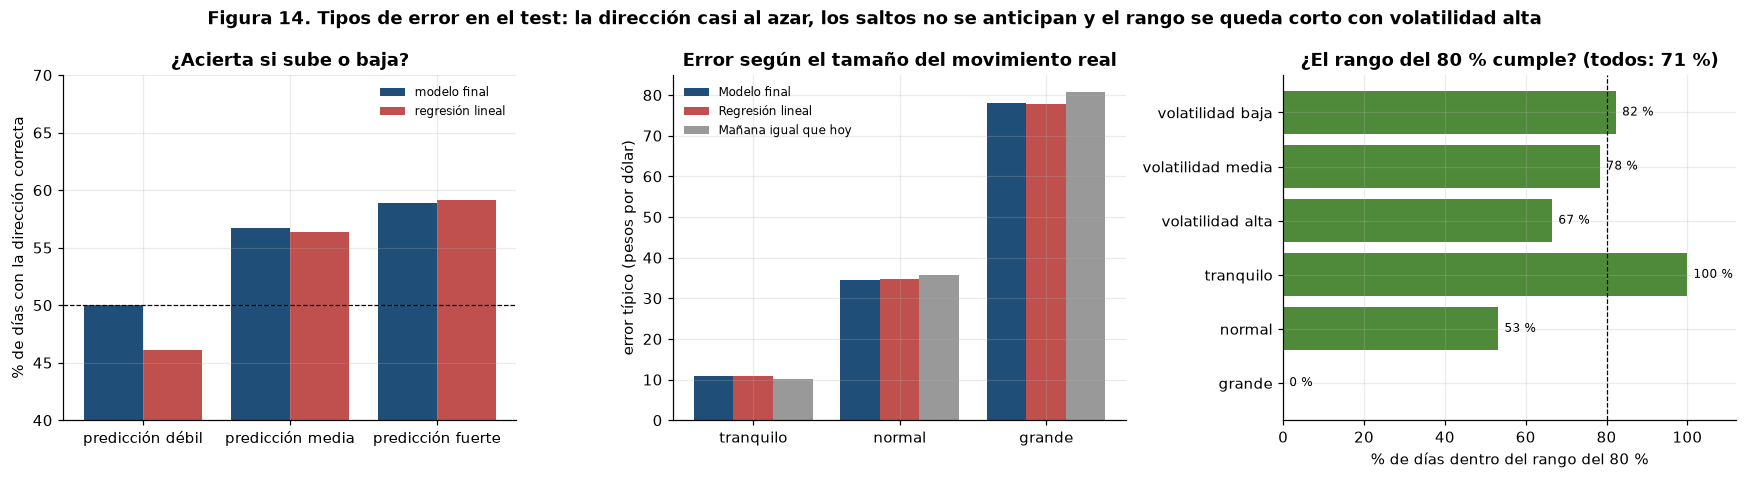

In [12]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.4))
eje = ejes[0]
fz = direccion.drop(index="todos")
x = np.arange(len(fz))
eje.bar(x - 0.2, fz["acierto_direccion_pct"], 0.4, color=COLORES[0], label="modelo final")
eje.bar(x + 0.2, fz["acierto_direccion_lineal_pct"], 0.4, color=COLORES[1], label="regresión lineal")
eje.axhline(50, color="k", lw=0.8, ls="--")
eje.set(xticks=x, xticklabels=fz.index, ylim=(40, 70), ylabel="% de días con la dirección correcta", title="¿Acierta si sube o baja?")
eje.legend(frameon=False, fontsize=8)
eje = ejes[1]
x = np.arange(len(por_tamano))
for j, (k, c) in enumerate(zip(MODELOS_ERR, [COLORES[0], COLORES[1], "0.6"])):
    eje.bar(x + (j - 1) * 0.27, por_tamano[f"mae_{k}"], 0.27, color=c, label=k)
eje.set(xticks=x, xticklabels=[t.split(" (")[0] for t in por_tamano.index], ylabel="error típico (pesos por dólar)",
        title="Error según el tamaño del movimiento real")
eje.legend(frameon=False, fontsize=8)
eje = ejes[2]
cv = cobertura.drop(index=["todos los días"])
eje.barh(range(len(cv))[::-1], cv.to_numpy(), color=COLORES[2])
for yy, v in zip(range(len(cv))[::-1], cv.to_numpy()):
    eje.annotate(f"{v:.0f} %", (v, yy), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
eje.axvline(80, color="k", lw=0.8, ls="--"); eje.set_xlim(0, 112)
eje.set(yticks=range(len(cv))[::-1], yticklabels=[t.split(" (")[0] for t in cv.index], xlabel="% de días dentro del rango del 80 %",
        title=f"¿El rango del 80 % cumple? (todos: {cobertura['todos los días']:.0f} %)")
fig.suptitle("Figura 14. Tipos de error en el test: la dirección casi al azar, los saltos no se anticipan y el rango se queda corto con volatilidad alta",
             fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "fig14_tipos_de_error"); plt.show()

### Lectura de la parte 3: tipos de error y qué implican
**1. La dirección es casi un volado (Tabla 15c, Figura 14 izquierda).** El modelo acierta si la TRM sube o baja el **55 %** de los días (la lineal, 54 %); el 59 % cuando su predicción es fuerte y el 50 % cuando es débil. Pero en el test la TRM bajó el 54 % de los días, así que decir siempre "baja" acertaba casi lo mismo: la diferencia **no es significativa** (p = 0,16). **No sirve para decidir el momento de comprar dólares.**

**2. El error lo deciden los días grandes (Tabla 15d, Figura 14 centro).**
- En días tranquilos (la mitad con movimientos más pequeños) el error típico es de **11 pesos**; en días normales, **35**; en el 10 % de días con movimientos más grandes, **78**. Ese 10 % de días produce el **53 %** del error cuadrático (el 5 %, el 37 %).
- Con volatilidad baja, media y alta, el error típico es de 19, 22 y 30 pesos. El test fue un periodo agitado: 667 de sus 1.080 días están en el tercio de mayor volatilidad del desarrollo.
- **No hay sesgo:** en promedio el modelo se equivoca −0,7 pesos (prácticamente cero). Se equivoca un poco más cuando la TRM sube (28 pesos) que cuando baja (26), lo mismo que le pasa a "mañana igual que hoy" (29 y 26): es una característica del mercado en ese periodo, no del modelo.
- En días tranquilos, "mañana igual que hoy" se equivoca un poco menos (10 pesos frente a 11), porque el modelo espera un movimiento que ese día no llega; en días normales y grandes, el modelo gana por 1 a 3 pesos.

**3. El rango del 80 % se queda corto cuando el mercado se agita (Tabla 15e, Figura 14 derecha).** Calculado con los errores de validación (antes de 2022), el rango contiene la TRM real el **71 %** de los días del test: el 82 % con volatilidad baja, el 78 % con media y solo el **67 % con alta**. (Por construcción, los días tranquilos siempre caen dentro y los grandes siempre fuera.) La aplicación usa el rango calculado con los errores del test, que por eso cubre el 80 % en 2022–2026; **una mejora natural es ensancharlo según la volatilidad reciente** (sección 8.4).

**4. Para un importador que compra USD 100.000 (Tabla 15f).**

| | Modelo final | "Mañana igual que hoy" |
|---|---|---|
| Error típico | 27,09 pesos por dólar → **COP 2,7 millones** | 27,48 → COP 2,7 millones |
| 9 de cada 10 días, error menor a | 55,7 pesos → COP 5,6 millones | 59,4 → COP 5,9 millones |
| Peor día del test | 158 pesos → COP 15,8 millones | 155 → COP 15,5 millones |

El modelo reduce el error típico en **0,39 pesos por dólar** (unos COP 39.000 en USD 100.000). Es poco, pero **es real**: frente a "mañana igual que hoy", Diebold-Mariano da p = 0,002. Es la memoria de un día de la TRM, medida en pesos.

**Qué decisiones apoya el modelo y cuáles no:**
- **Sí:** un **valor de referencia** para presupuestar el día siguiente y un **orden de magnitud del riesgo** (unos ±27 pesos por dólar un día típico; el doble en uno de cada diez días), más amplio cuando el mercado está agitado.
- **No:** elegir el día para comprar (la dirección es casi al azar), anticipar los saltos grandes (como el −3,6 % de octubre de 2023) ni pronosticar semanas o meses. Para protegerse de los días grandes, la herramienta es una cobertura (por ejemplo, un forward), no un pronóstico.

## 4. Alcance de las conclusiones
Qué se puede afirmar con estos resultados, qué solo con cautela y qué no. Cada fila cita su evidencia.

In [13]:
t11 = pd.read_csv(cfg.TABLAS / "tab11_boosting_vs_base.csv", index_col=0)
t11a = pd.read_csv(cfg.TABLAS / "tab11a_aporte_macro_formal.csv", index_col=0)
alcance = pd.DataFrame([
    ["Sí", "A un día, el petróleo, el dólar global y el diferencial de tasas no mejoran la predicción de la TRM",
     f"Ninguna versión con macro predice mejor que la misma sin ellas (Diebold-Mariano en validación, p de {es(t11a['p_valor'].min())} a {es(t11a['p_valor'].max())}); en el test empeoran (nb 06, 08)"],
    ["Sí", "Ningún boosting predice mejor que una regresión lineal sobre los movimientos de la TRM",
     f"p de {es(t11['p_valor'].min())} a {es(t11['p_valor'].max())} en validación; en el test, p = 0,90 (nb 08)"],
    ["Sí", "La TRM tiene una memoria de un día pequeña pero real",
     f"Mañana repite cerca del 17–20 % del movimiento de hoy; el modelo le gana a 'mañana igual que hoy' por {es(importador.iloc[2, 0] - importador.iloc[0, 0])} pesos por dólar, "
     f"p = {es(dm_ing['p_valor'], 3)} (parte 3)"],
    ["Sí", "El método del artículo, aplicado tal cual, no sirve para la TRM, y su R² en nivel no mide capacidad de predecir",
     "Techo de extrapolación (nb 04); con sus propios datos, su R² no supera a copiar el precio de hoy (nb 08b)"],
    ["Con cautela", "Todo lo anterior vale para 2003–2026 y para un solo periodo de test (2022–2026), agitado y ya abierto en la Entrega 2",
     "Un periodo distinto podría mover las diferencias de centavos; la conclusión de fondo (no hay señal macro a un día) se repite en validación, test y nb 07"],
    ["Con cautela", "La forma en S y la asimetría del efecto (techo de +35 pb al subir y −24 pb al bajar)",
     f"El techo se forma con los pocos días de movimientos de más de ~1,5 % (63 días de 4.320 en el desarrollo superan el 1,9 %) (parte 1)"],
    ["Con cautela", "El diferencial de tasas daña por un cambio de régimen",
     "Sus valores altos solo ocurrieron en 2008–2009 dentro del desarrollo; con más episodios, su relación con la TRM podría estabilizarse (nb 08)"],
    ["No", "Que el petróleo, el dólar global o las tasas no afecten la TRM",
     "La conclusión es predictiva y a un día, no causal: esas variables pueden moverse junto con la TRM el mismo día o pesar en semanas o meses; lo que no hacen es anticipar el movimiento de mañana con el dato de hoy"],
    ["No", "Conclusiones para horizontes de semanas o meses, o para movimientos dentro del día",
     "Solo se evaluó el día siguiente (horizonte de la Entrega 1)"],
    ["No", "Que el boosting no sirva para predecir divisas",
     "Aquí no hay señal no lineal que aprovechar (EDA E9); con otras variables, horizontes o datos de mayor frecuencia, el resultado podría ser distinto"],
    ["No", "Que el modelo sirva para elegir el día de compra",
     f"Acierta la dirección el {direccion.loc['todos', 'acierto_direccion_pct']:.0f} % de los días, no más que decir siempre lo más frecuente (p = {es(binom.pvalue)}) (parte 3)"],
    ["No", "Que funcione igual en regímenes que no están en los datos (p. ej., controles cambiarios o una crisis distinta)",
     "El modelo solo conoce 2003–2026; el semáforo de la aplicación avisa cuando los datos salen de lo visto"],
], columns=["se_puede_afirmar", "afirmacion", "evidencia"])
guardar_tabla(alcance.set_index("afirmacion"), "tab15g_alcance")
with pd.option_context("display.max_colwidth", 200):
    display(alcance)

,se_puede_afirmar,afirmacion,evidencia
0,Sí,"A un día, el petróleo, el dólar global y el diferencial de tasas no mejoran la predicción de la TRM","Ninguna versión con macro predice mejor que la misma sin ellas (Diebold-Mariano en validación, p de 0,12 a 0,95); en el test empeoran (nb 06, 08)"
1,Sí,Ningún boosting predice mejor que una regresión lineal sobre los movimientos de la TRM,"p de 0,32 a 0,82 en validación; en el test, p = 0,90 (nb 08)"
2,Sí,La TRM tiene una memoria de un día pequeña pero real,"Mañana repite cerca del 17–20 % del movimiento de hoy; el modelo le gana a 'mañana igual que hoy' por 0,39 pesos por dólar, p = 0,002 (parte 3)"
3,Sí,"El método del artículo, aplicado tal cual, no sirve para la TRM, y su R² en nivel no mide capacidad de predecir","Techo de extrapolación (nb 04); con sus propios datos, su R² no supera a copiar el precio de hoy (nb 08b)"
4,Con cautela,"Todo lo anterior vale para 2003–2026 y para un solo periodo de test (2022–2026), agitado y ya abierto en la Entrega 2","Un periodo distinto podría mover las diferencias de centavos; la conclusión de fondo (no hay señal macro a un día) se repite en validación, test y nb 07"
5,Con cautela,La forma en S y la asimetría del efecto (techo de +35 pb al subir y −24 pb al bajar),"El techo se forma con los pocos días de movimientos de más de ~1,5 % (63 días de 4.320 en el desarrollo superan el 1,9 %) (parte 1)"
6,Con cautela,El diferencial de tasas daña por un cambio de régimen,"Sus valores altos solo ocurrieron en 2008–2009 dentro del desarrollo; con más episodios, su relación con la TRM podría estabilizarse (nb 08)"
7,No,"Que el petróleo, el dólar global o las tasas no afecten la TRM","La conclusión es predictiva y a un día, no causal: esas variables pueden moverse junto con la TRM el mismo día o pesar en semanas o meses; lo que no hacen es anticipar el movimiento de mañana con ..."
8,No,"Conclusiones para horizontes de semanas o meses, o para movimientos dentro del día",Solo se evaluó el día siguiente (horizonte de la Entrega 1)
9,No,Que el boosting no sirva para predecir divisas,"Aquí no hay señal no lineal que aprovechar (EDA E9); con otras variables, horizontes o datos de mayor frecuencia, el resultado podría ser distinto"


## 5. Qué significa para quien usa la TRM

**Para un importador o una empresa con pagos en dólares.**
- **Qué le dice el modelo:** la TRM de mañana suele parecerse mucho a la de hoy, más una pequeña parte del movimiento de hoy: cerca de una quinta parte, con tope. Si hoy subió 1 %, espera que mañana suba unos 0,2 %; si hoy saltó 3 %, no espera más de 0,35 %.
- **Cuánto se puede equivocar:** en una compra de USD 100.000, el error típico de un día es de unos **COP 2,7 millones** (27 pesos por dólar); uno de cada diez días, más de COP 5,6 millones; el peor día del periodo 2022–2026, COP 15,8 millones. Con el mercado agitado, el error crece.
- **Para qué usarlo:** como un valor de referencia para presupuestar el día siguiente y como medida del riesgo diario, mirando el semáforo de la aplicación (si dice volatilidad alta, el rango real es más amplio).
- **Para qué no usarlo:** para decidir si comprar hoy o mañana (acierta la dirección casi como una moneda) ni para planear con semanas de anticipación. Si el riesgo de un día malo es importante para la empresa, la herramienta adecuada es una cobertura (un forward), no un pronóstico.

**Para el Banco de la República.** Con datos diarios, el petróleo, el dólar global y el diferencial de tasas del día anterior no permiten anticipar el movimiento de la TRM del día siguiente. El caso del diferencial muestra además que su relación con la TRM depende del contexto: en 2008–2009 un diferencial alto coincidió con devaluación (crisis), y en 2022–2026 con revaluación (tasas altas contra la inflación). Leer el efecto de las tasas sobre la TRM requiere horizontes más largos y separar los episodios, no un modelo de pronóstico diario.

**En una frase (para el informe):** *el modelo final aprendió que mañana la TRM repite una pequeña parte del movimiento de hoy, con un tope; esa memoria es real pero vale unos 0,4 pesos por dólar frente a no usar modelo, no sirve para elegir el día de compra y no anticipa los saltos grandes, que son los que más cuestan.*